<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-04/lab-012-onsager.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 012 <br>
**Reading:** slides *Onsager's Exact Solution of the 2D Ising Model* (supplement to Lecture 4); Lecture Notes, Chapter 2, Section *Deep Learning in the Classical 2D Ising Model* (subsection *Onsager's solution*)
<hr/>

# Lab 012 — Onsager's exact solution

In Lab 010 and Lab 011 a convolutional network located the critical temperature of the two-dimensional (2D) Ising model from raw spin images. In the lecture we asked where the exact critical temperature
$$T_c=\frac{2}{\ln\big(1+\sqrt2\big)}\approx2.2692 \tag{1}$$
comes from. Each result of the slides *Onsager's Exact Solution* is reproduced below by a computation.

We begin with what it means to "solve" the model: $\ln Z$ of a finite lattice computed by brute force, which turns out to be always smooth. The one-dimensional chain then introduces the transfer matrix, numerically and exactly. In two dimensions the transfer matrix has size $2^L\times2^L$ for a strip of width $L$; with it we watch the free energy converge to Onsager's, the specific-heat peak grow and move towards $T_c$, and the correlation length detect $T_c$. The high- and low-temperature expansions of $Z$ lead to Kramers–Wannier duality and to the self-dual coupling $K_c$. From Onsager's formula we obtain $f$, $u$, $c$ and Yang's magnetisation $M$, and we derive the energy per spin at $T_c$, $-\sqrt2\,J$, both numerically and from duality alone. The last part measures the critical exponents from the exact formulas and from the transfer matrix, compares mean-field theory with the exact solution, and tests universality on the triangular lattice.

We use units in which $J$ and $k_B$ are one, with no external field unless stated otherwise. The dimensionless coupling is
$$K=\frac{J}{T}=\beta J. \tag{2}$$

> **Running in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. Only `numpy`, `scipy` and `matplotlib` are needed; they are pre-installed in Colab, no `pip install` required. No data are downloaded.
> 4. The whole notebook runs in a few minutes on a laptop. The slowest cells (transfer matrices of size $2^{10}\times2^{10}$ and $2^{12}\times2^{12}$) print their running time.
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.integrate import quad
from scipy.special import ellipkm1
from scipy.integrate import IntegrationWarning
import warnings
from scipy.optimize import brentq
from scipy.linalg import eigh
from scipy.sparse.linalg import eigs, eigsh

# UJ colours
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
blues = LinearSegmentedColormap.from_list("uj_blues", ["#9CC3E6", UJNavy])   # light -> dark: small L -> large L
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": UJGray, "axes.titlesize": 11, "axes.titlecolor": UJNavy,
                     "axes.prop_cycle": plt.cycler(color=[UJBlue, DSOrange, UJNavy, UJGray])})

TC = 2.0 / np.log(1.0 + np.sqrt(2.0))      # Onsager's critical temperature (derived in Section 5)
KC = 1.0 / TC
print(f"T_c = 2/ln(1+sqrt 2) = {TC:.10f},   K_c = 1/T_c = {KC:.10f}")

T_c = 2/ln(1+sqrt 2) = 2.2691853142,   K_c = 1/T_c = 0.4406867935


<hr/>
## 1. The free energy and its derivatives

To "solve" the model means to know the **free energy per spin**, because everything else follows from it:
$$
f(T) = -T\lim_{N\to\infty}\frac1N\ln Z, \tag{3}
$$
$$
Z=\sum_{\{s_i\}}e^{-H(\{s_i\})/T}, \tag{4}
$$
$$
H = -\sum_{\langle i,j\rangle}s_is_j . \tag{5}
$$
Observables are derivatives with respect to the inverse temperature $\beta$:
$$
u = \frac{\partial(\beta f)}{\partial\beta} = \frac{\langle H\rangle}{N}, \tag{6}
$$
$$
c = \frac{\partial u}{\partial T} = \frac{\langle H^2\rangle-\langle H\rangle^2}{NT^2}. \tag{7}
$$

### 1.1 Brute force on a tiny lattice
On an $L\times L$ torus there are $2^{L^2}$ configurations. For the $4\times4$ lattice that is 65 536, which is easy. We store every configuration as a row of $\pm1$: the binary digits of an integer $n$ from 0 to $2^N-1$ give the spins, a digit 0 being read as the spin $+1$ and a digit 1 as $-1$.

Each configuration has the energy
$$E = -2N + 2b, \tag{8}$$
where $b$ is the number of **broken bonds** (antiparallel neighbours): the torus has two bonds per site, and each contributes $-1$ if satisfied and $+1$ if broken. So $Z$ is determined by the histogram $n_b$ (the *density of states*):
$$
Z(T) = \sum_{b} n_b\, e^{-(-2N+2b)/T}. \tag{9}
$$

In [2]:
def all_configs(n):
    # all 2^n configurations of n spins, as rows of +-1 (bit k of the row index -> spin k)
    bits = (np.arange(2**n)[:, None] >> np.arange(n)) & 1
    return (1 - 2 * bits).astype(np.int8)

def torus_energies(L):
    # energies of all 2^(L*L) configurations of the L x L periodic square lattice (J = 1)
    S = all_configs(L * L).reshape(-1, L, L).astype(np.int32)
    return -(S * np.roll(S, 1, axis=1)).sum(axis=(1, 2)) - (S * np.roll(S, 1, axis=2)).sum(axis=(1, 2))

dos = {}
for L in (3, 4):
    t0 = time.perf_counter()
    E = torus_energies(L)
    N = L * L
    b = (E + 2 * N) // 2                         # number of broken bonds
    dos[L] = np.bincount(b, minlength=2 * N + 1)  # n_b
    print(f"L = {L}: {2**N:6d} configurations enumerated in {time.perf_counter()-t0:.2f} s,  sum n_b = {dos[L].sum()}")
print("4x4 torus, number of configurations with b broken bonds:")
print({int(k): int(v) for k, v in enumerate(dos[4]) if v})

L = 3:    512 configurations enumerated in 0.00 s,  sum n_b = 512
L = 4:  65536 configurations enumerated in 0.02 s,  sum n_b = 65536
4x4 torus, number of configurations with b broken bonds:
{0: 2, 4: 32, 6: 64, 8: 424, 10: 1728, 12: 6688, 14: 13568, 16: 20524, 18: 13568, 20: 6688, 22: 1728, 24: 424, 26: 64, 28: 32, 32: 2}


### 1.2 Thermodynamics of the finite lattice
With $n_b$ in hand, $\ln Z$, $u$ and $c$ are smooth functions of $T$:
$$
\ln Z = \ln\sum_b n_b e^{(2N-2b)/T}, \tag{10}
$$
$$
u = \frac{\sum_b n_b E_b e^{-E_b/T}}{NZ}, \tag{11}
$$
$$
c = \frac{\langle E^2\rangle - \langle E\rangle^2}{NT^2}. \tag{12}
$$
$Z$ is a **finite sum of exponentials**, positive for every real $T$, so $\ln Z$ is analytic: a finite lattice has *no* phase transition.
A singularity can only appear in the limit of infinitely many spins.

L = 3: specific-heat maximum c = 0.653 at T = 2.474
L = 4: specific-heat maximum c = 0.816 at T = 2.440


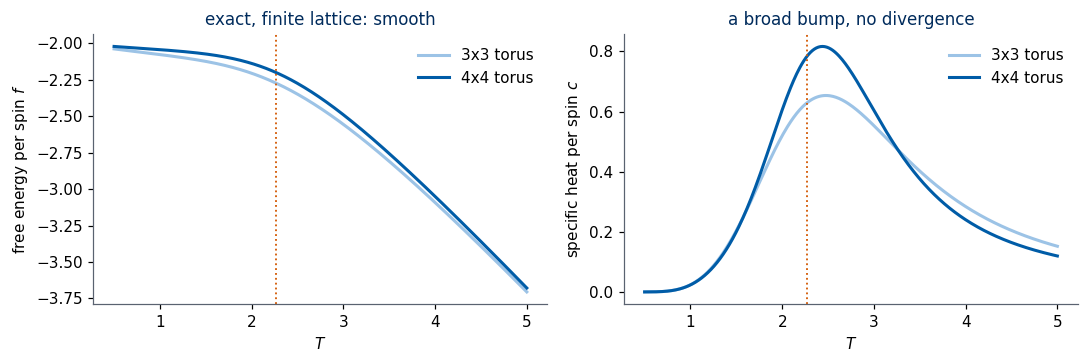

In [3]:
def thermo_from_dos(nb, N, T):
    # ln Z / N, u and c per spin from the histogram n_b of broken bonds
    T = np.atleast_1d(T)[:, None]
    Eb = -2 * N + 2 * np.arange(len(nb))
    logw = np.log(np.where(nb > 0, nb, 1)) - Eb / T
    logw = np.where(nb > 0, logw, -np.inf)
    shift = logw.max(axis=1, keepdims=True)                  # avoid overflow
    w = np.exp(logw - shift); Zr = w.sum(axis=1, keepdims=True); p = w / Zr
    E1 = (p * Eb).sum(1); E2 = (p * Eb**2).sum(1)
    lnZ = (np.log(Zr) + shift)[:, 0]
    return lnZ / N, E1 / N, (E2 - E1**2) / (N * T[:, 0]**2)

T = np.linspace(0.5, 5.0, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for L, col in [(3, "#9CC3E6"), (4, UJBlue)]:
    lnz, u, c = thermo_from_dos(dos[L], L * L, T)
    ax[0].plot(T, -T * lnz, color=col, lw=2, label=f"{L}x{L} torus")
    ax[1].plot(T, c, color=col, lw=2, label=f"{L}x{L} torus")
    print(f"L = {L}: specific-heat maximum c = {c.max():.3f} at T = {T[c.argmax()]:.3f}")
for a in ax:
    a.axvline(TC, color=DSOrange, ls=":", lw=1.2); a.set_xlabel("$T$"); a.legend(frameon=False)
ax[0].set_ylabel("free energy per spin $f$"); ax[1].set_ylabel("specific heat per spin $c$")
ax[0].set_title("exact, finite lattice: smooth"); ax[1].set_title("a broad bump, no divergence")
plt.tight_layout(); plt.show()

The specific heat has a smooth bump. Brute force cannot go much further: the $6\times6$ lattice already has $2^{36}$, about $7\times10^{10}$, configurations,
and the $20\times20$ images of Lab 010 have $2^{400}$. We need a smarter way to do the sum — the **transfer matrix**.

<hr/>
## 2. The 1D chain and the transfer matrix

The one-dimensional (1D) chain shows the transfer-matrix idea in its simplest form. Take
$$H = -\sum_i s_is_{i+1} - h\sum_i s_i \tag{13}$$
on a ring of $N$ spins. With $J$ set to 1 the coupling $K$ of equation (2) is $\beta$ itself, and we write the reduced field as
$$\tilde h = \beta h. \tag{14}$$
The Boltzmann weight is a product of **bond factors**
$$
e^{-\beta H} = \prod_{i=1}^N \mathsf T_{s_is_{i+1}}, \tag{15}
$$
$$
\mathsf T_{ss'} = e^{Kss' + \frac{\tilde h}{2}(s+s')}, \tag{16}
$$
$$
\mathsf T = \begin{pmatrix} e^{K+\tilde h} & e^{-K}\\ e^{-K} & e^{K-\tilde h}\end{pmatrix}. \tag{17}
$$
The sum over all $2^N$ configurations is a matrix product, closed into a trace by the periodic boundary:
$$
Z = \sum_{s_1,\dots,s_N}\mathsf T_{s_1s_2}\mathsf T_{s_2s_3}\cdots\mathsf T_{s_Ns_1} = \operatorname{Tr}\mathsf T^N = \lambda_+^N + \lambda_-^N . \tag{18}
$$
The eigenvalues of a symmetric $2\times2$ matrix with diagonal entries $a$, $d$ and off-diagonal entry $b$ are
$$\lambda=\frac{a+d}{2}\pm\sqrt{\left(\frac{a-d}{2}\right)^2+b^2}, \tag{19}$$
which for the matrix (17) gives
$$
\lambda_\pm = e^{K}\cosh\tilde h \pm \sqrt{e^{2K}\sinh^2\tilde h + e^{-2K}}, \tag{20}
$$
and in zero field
$$\lambda_+ = 2\cosh K,\qquad \lambda_- = 2\sinh K . \tag{21}$$
The trace in equation (18) is compared with the brute-force sum, and equation (20) with the eigenvalues returned by `numpy`.

In [4]:
def Z_chain_brute(N, K, ht):
    S = all_configs(N).astype(float)
    E_over_T = -K * (S * np.roll(S, -1, axis=1)).sum(1) - ht * S.sum(1)     # beta*H
    return np.exp(-E_over_T).sum()

def T_chain(K, ht):
    return np.array([[np.exp(K + ht), np.exp(-K)], [np.exp(-K), np.exp(K - ht)]])

N = 14
for K, ht in [(0.3, 0.0), (1.0, 0.0), (0.7, 0.4), (1.5, -0.2)]:
    Zb = Z_chain_brute(N, K, ht)
    Zt = np.trace(np.linalg.matrix_power(T_chain(K, ht), N))
    lam_num = np.sort(np.linalg.eigvalsh(T_chain(K, ht)))[::-1]
    root = np.sqrt(np.exp(2 * K) * np.sinh(ht)**2 + np.exp(-2 * K))
    lam_exact = np.array([np.exp(K) * np.cosh(ht) + root, np.exp(K) * np.cosh(ht) - root])
    print(f"K={K:3.1f}, beta*h={ht:4.1f}:  Z brute = {Zb:.10e}   Tr T^N = {Zt:.10e}   "
          f"max|lambda_numpy - lambda_formula| = {np.abs(lam_num - lam_exact).max():.1e}")

K=0.3, beta*h= 0.0:  Z brute = 3.0480162419e+04   Tr T^N = 3.0480162419e+04   max|lambda_numpy - lambda_formula| = 1.1e-16
K=1.0, beta*h= 0.0:  Z brute = 7.2668862529e+06   Tr T^N = 7.2668862529e+06   max|lambda_numpy - lambda_formula| = 0.0e+00
K=0.7, beta*h= 0.4:  Z brute = 9.1298799858e+06   Tr T^N = 9.1298799858e+06   max|lambda_numpy - lambda_formula| = 8.9e-16
K=1.5, beta*h=-0.2:  Z brute = 2.3316896955e+10   Tr T^N = 2.3316896955e+10   max|lambda_numpy - lambda_formula| = 4.4e-16


### 2.1 Free energy and correlations of the infinite chain
For a long chain
$$
\ln Z = N\ln\lambda_+ + \ln\Big(1 + \big(\lambda_-/\lambda_+\big)^N\Big)\;\xrightarrow{N\to\infty}\;N\ln\lambda_+ , \tag{22}
$$
so
$$
f = -T\ln\big(2\cosh(1/T)\big), \tag{23}
$$
smooth at every positive temperature: there is **no phase transition** in 1D (Ising, 1925). The spin–spin correlation is also a matrix product, with the diagonal matrix $\sigma^z$ whose entries are 1 and $-1$:
$$
\langle s_0s_r\rangle = \frac{\operatorname{Tr}\big(\sigma^z\mathsf T^r\sigma^z\mathsf T^{N-r}\big)}{\operatorname{Tr}\mathsf T^N}
\;\xrightarrow{N\to\infty}\; \Big(\frac{\lambda_-}{\lambda_+}\Big)^r = (\tanh K)^r = e^{-r/\xi}, \tag{24}
$$
$$
\xi = -\frac{1}{\ln\tanh K}. \tag{25}
$$
$\xi$ is finite at every positive temperature and diverges only at zero temperature.

K = 0.5: max |<s0 sr> - tanh(K)^r| over r<25 = 7.1e-17,  xi = 1.295
K = 1.0: max |<s0 sr> - tanh(K)^r| over r<25 = 1.1e-16,  xi = 3.672
K = 1.5: max |<s0 sr> - tanh(K)^r| over r<25 = 4.4e-16,  xi = 10.034


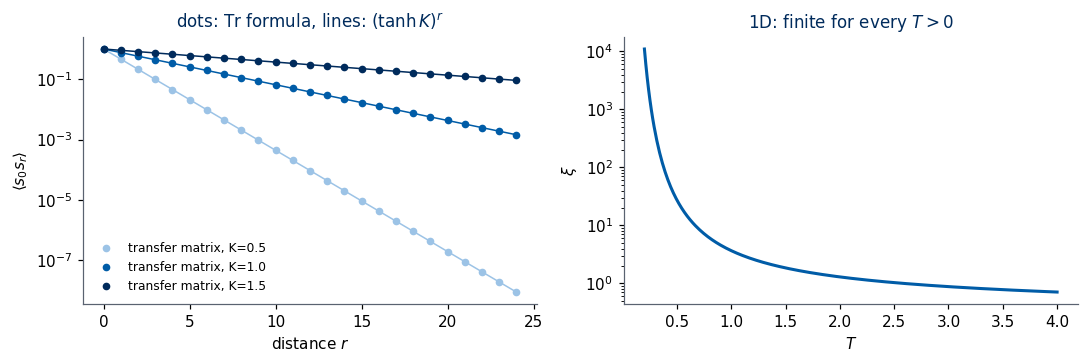

In [5]:
sz = np.diag([1.0, -1.0])
N, r = 400, np.arange(0, 25)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for K, col in [(0.5, "#9CC3E6"), (1.0, UJBlue), (1.5, UJNavy)]:
    Tm = T_chain(K, 0.0) / (2 * np.cosh(K))                 # rescaled, to avoid overflow; ratios are unchanged
    corr = [np.trace(sz @ np.linalg.matrix_power(Tm, k) @ sz @ np.linalg.matrix_power(Tm, N - k)) /
            np.trace(np.linalg.matrix_power(Tm, N)) for k in r]
    ax[0].semilogy(r, corr, "o", color=col, ms=4, label=f"transfer matrix, K={K}")
    ax[0].semilogy(r, np.tanh(K)**r, "-", color=col, lw=1)
    print(f"K = {K}: max |<s0 sr> - tanh(K)^r| over r<25 = {np.max(np.abs(np.array(corr) - np.tanh(K)**r)):.1e},"
          f"  xi = {-1/np.log(np.tanh(K)):.3f}")
ax[0].set_xlabel("distance $r$"); ax[0].set_ylabel(r"$\langle s_0 s_r\rangle$"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title(r"dots: $\mathrm{Tr}$ formula, lines: $(\tanh K)^r$")
Tg = np.linspace(0.2, 4, 300)
ax[1].plot(Tg, -1 / np.log(np.tanh(1 / Tg)), color=UJBlue, lw=2)
ax[1].set_yscale("log"); ax[1].set_xlabel("$T$"); ax[1].set_ylabel(r"$\xi$"); ax[1].set_title("1D: finite for every $T>0$")
plt.tight_layout(); plt.show()

The 1D chain teaches the lesson we carry into two dimensions: for a long system only the largest eigenvalue matters,
$$\ln Z \approx N\ln\lambda_{\max}, \tag{26}$$
and the correlation length is set by the ratio of the two largest eigenvalues,
$$\xi = \frac{1}{\ln(\lambda_{\max}/\lambda_2)}. \tag{27}$$

<hr/>
## 3. The 2D transfer matrix

Take a strip of **width $L$** (periodic in the vertical direction) and of a length $L'$ that grows without bound. One column $\sigma$, the spins $s_1,\dots,s_L$, has $2^L$ states. Bonds inside a column and between neighbouring columns give
$$
Z = \operatorname{Tr}\mathsf V^{L'}, \tag{28}
$$
$$
\mathsf V_{\sigma\sigma'} = \exp\Big[K\sum_{i=1}^L s_is_i' + \frac K2\sum_{i=1}^L\big(s_is_{i+1} + s'_is'_{i+1}\big)\Big], \tag{29}
$$
where the vertical bonds are split half–half between the two columns so that $\mathsf V$ is symmetric. Then
$$
f_L(T) = -\frac{T}{L}\ln\lambda_0(L), \tag{30}
$$
$$
\xi_L = \frac{1}{\ln(\lambda_0/\lambda_1)}, \tag{31}
$$
with $\lambda_0$ and $\lambda_1$ the largest and the second-largest eigenvalue. Onsager's free energy is the limit
$$f = \lim_{L\to\infty}f_L . \tag{32}$$

Symmetry halves the work. Reversing all spins of a column does not change $\mathsf V$, and in our bit encoding it maps the index $n$ to
$$\bar n = 2^L-1-n. \tag{33}$$
Pairing each state with its reversed partner splits $\mathsf V$ into an even and an odd block,
$$\mathsf V^{\pm}_{nm}=\mathsf V_{nm}\pm\mathsf V_{n\bar m}, \tag{34}$$
each of size $2^{L-1}$. $\lambda_0$ is the top of the even block (Perron–Frobenius: all entries are positive), and $\lambda_1$ the top of the odd block, the eigenvalue that describes how a single spin's orientation is remembered along the strip.

The construction is first tested on a known case: on an $L\times L'$ torus equation (28) is exact, so for $4\times4$ it must agree with the brute-force histogram of Section 1.

In [6]:
def transfer_matrix(L, K, lattice="square"):
    # V[sigma, sigma'] for a periodic column of L spins; 'triangular' adds the diagonal bonds s_i s'_{i+1} (Section 10)
    S = all_configs(L).astype(float)
    intra = (S * np.roll(S, -1, axis=1)).sum(1)                 # sum_i s_i s_{i+1} inside a column
    inter = S @ S.T                                             # sum_i s_i s'_i
    if lattice == "triangular":
        inter = inter + S @ np.roll(S, -1, axis=1).T            # sum_i s_i s'_{i+1}
    return np.exp(K * (inter + 0.5 * (intra[:, None] + intra[None, :])))

def top_eigenvalue(A, symmetric):
    n = A.shape[0]
    if symmetric and n <= 64:
        return eigh(A, eigvals_only=True, subset_by_index=[n - 1, n - 1])[0]
    if symmetric:
        return eigsh(A, k=1, which="LA", tol=0)[0][0]           # Lanczos: only the top eigenvalue
    if n <= 64:
        return np.max(np.linalg.eigvals(A).real)
    return eigs(A, k=1, which="LR", tol=1e-14)[0][0].real

def lambda01(L, K, lattice="square"):
    # (lambda_0, lambda_1): largest eigenvalues in the spin-flip even and odd sectors
    V = transfer_matrix(L, K, lattice)
    n = V.shape[0] // 2
    Vflip = V[:, ::-1]                                          # column m -> its flipped partner 2^L-1-m
    sym = lattice == "square"
    return (top_eigenvalue(V[:n, :n] + Vflip[:n, :n], sym),
            top_eigenvalue(V[:n, :n] - Vflip[:n, :n], sym))

# check: Z of the 4x4 torus from Tr V^4 versus the brute-force histogram
for T in (1.5, TC, 3.5):
    V = transfer_matrix(4, 1 / T)
    Z_tm = np.trace(np.linalg.matrix_power(V, 4))
    lnz_dos, _, _ = thermo_from_dos(dos[4], 16, T)
    print(f"T = {T:.4f}:  ln Z (Tr V^4) = {np.log(Z_tm):.12f}   ln Z (brute force) = {16 * lnz_dos[0]:.12f}")

T = 1.5000:  ln Z (Tr V^4) = 22.117013911716   ln Z (brute force) = 22.117013911716
T = 2.2692:  ln Z (Tr V^4) = 15.521915458755   ln Z (brute force) = 15.521915458755
T = 3.5000:  ln Z (Tr V^4) = 12.600438025330   ln Z (brute force) = 12.600438025330


### 3.1 Free energy and specific heat of strips
For the widths 4 to 10 we compute
$$c_L = -T\,\frac{\partial^2 f_L}{\partial T^2} \tag{35}$$
by finite differences on a fine grid; the eigenvalues are accurate to machine precision, so the second difference is reliable. Onsager's $f$ (Section 6) is plotted for comparison.

strip transfer matrices: 4.6 s


L =  4:  c_max = 0.8728 at T = 2.210;   |f_L - f| at T = 1.5, T_c, 3.5:  3.5e-03, 3.9e-02, 1.1e-02
L =  6:  c_max = 1.0739 at T = 2.240;   |f_L - f| at T = 1.5, T_c, 3.5:  3.7e-04, 1.7e-02, 1.3e-03
L =  8:  c_max = 1.2160 at T = 2.250;   |f_L - f| at T = 1.5, T_c, 3.5:  4.8e-05, 9.4e-03, 2.1e-04
L = 10:  c_max = 1.3262 at T = 2.260;   |f_L - f| at T = 1.5, T_c, 3.5:  6.8e-06, 6.0e-03, 3.5e-05


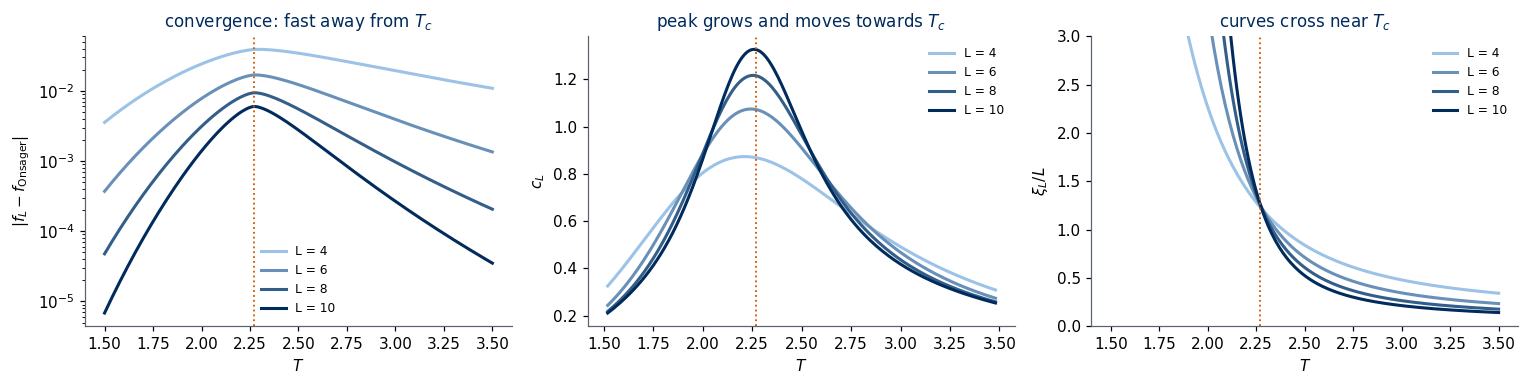

In [7]:
def f_onsager(T):
    # Onsager 1944: -beta f = ln(2 cosh 2K) + (1/2pi) int_0^pi ln[(1 + sqrt(1 - kappa^2 sin^2 phi))/2] dphi
    K = 1.0 / T
    k = 2 * np.sinh(2 * K) / np.cosh(2 * K)**2
    g = lambda p: np.log(0.5 * (1 + np.sqrt(max(0.0, 1 - k**2 * np.sin(p)**2))))
    with warnings.catch_warnings():                 # at T = T_c the integrand has a kink; quad warns but the result is accurate
        warnings.simplefilter("ignore", IntegrationWarning)
        I, _ = quad(g, 0, np.pi, points=[np.pi / 2], limit=200, epsabs=1e-13, epsrel=1e-13)
    return -T * (np.log(2 * np.cosh(2 * K)) + I / (2 * np.pi))

Ls = [4, 6, 8, 10]
Tgrid = np.linspace(1.5, 3.5, 201); dT = Tgrid[1] - Tgrid[0]
strip = {}
t0 = time.perf_counter()
for L in Ls:
    lam = np.array([lambda01(L, 1 / T) for T in Tgrid])
    fL = -Tgrid * np.log(lam[:, 0]) / L
    cL = -Tgrid * np.gradient(np.gradient(fL, dT), dT)
    xiL = 1 / np.log(lam[:, 0] / lam[:, 1])
    strip[L] = dict(f=fL, c=cL, xi=xiL)
print(f"strip transfer matrices: {time.perf_counter() - t0:.1f} s")
f_inf = np.array([f_onsager(T) for T in Tgrid])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for i, L in enumerate(Ls):
    col = blues(i / (len(Ls) - 1))
    ax[0].semilogy(Tgrid, np.abs(strip[L]["f"] - f_inf), color=col, lw=2, label=f"L = {L}")
    s = slice(2, -2)                                                   # drop the one-sided ends of np.gradient
    ax[1].plot(Tgrid[s], strip[L]["c"][s], color=col, lw=2, label=f"L = {L}")
    k = np.argmax(strip[L]["c"][s])
    print(f"L = {L:2d}:  c_max = {strip[L]['c'][s][k]:.4f} at T = {Tgrid[s][k]:.3f};   "
          f"|f_L - f| at T = 1.5, T_c, 3.5:  {abs(strip[L]['f'][0]-f_inf[0]):.1e}, "
          f"{abs(-TC*np.log(lambda01(L, KC)[0])/L - f_onsager(TC)):.1e}, {abs(strip[L]['f'][-1]-f_inf[-1]):.1e}")
    ax[2].plot(Tgrid, strip[L]["xi"] / L, color=col, lw=2, label=f"L = {L}")
for a in ax:
    a.axvline(TC, color=DSOrange, ls=":", lw=1.2); a.set_xlabel("$T$"); a.legend(frameon=False, fontsize=8)
ax[0].set_ylabel(r"$|f_L - f_{\rm Onsager}|$"); ax[0].set_title("convergence: fast away from $T_c$")
ax[1].set_ylabel("$c_L$"); ax[1].set_title("peak grows and moves towards $T_c$")
ax[2].set_ylabel(r"$\xi_L / L$"); ax[2].set_ylim(0, 3); ax[2].set_title(r"curves cross near $T_c$")
plt.tight_layout(); plt.show()

**Away from $T_c$**, $f_L$ converges to Onsager's $f$ exponentially fast in $L$: the correlation length is finite, and a strip wider than $\xi$ is effectively "infinite". **At $T_c$** the convergence is only a power law, because the strip is never wider than the infinite correlation length; the peak of $c_L$ grows (slowly, since the divergence will turn out to be logarithmic, Section 8) and moves towards $T_c$.

The ratio $\xi_L/L$ **decreases** with $L$ above $T_c$ (finite $\xi$), **increases** below $T_c$ (two degenerate ordered states, so that $\lambda_1$ approaches $\lambda_0$), and is $L$-independent exactly at $T_c$, where the only length scale is $L$ itself. The crossing points of the curves for neighbouring widths therefore locate $T_c$. This is the same logic as the finite-size analysis of the CNN, but with an exact algorithm.

In [8]:
def xi_over_L(L, T, lattice="square"):
    l0, l1 = lambda01(L, 1 / T, lattice)
    return 1 / np.log(l0 / l1) / L

print(" L, L+2   crossing T*(L)      T*(L) - T_c")
for L in (4, 6, 8, 10):
    t0 = time.perf_counter()
    Tx = brentq(lambda T: xi_over_L(L, T) - xi_over_L(L + 2, T), 2.0, 2.6, xtol=1e-12)
    print(f"{L:2d}, {L+2:2d}   {Tx:.8f}      {Tx - TC:+.2e}     ({time.perf_counter()-t0:.1f} s)")
print(f"exact T_c = {TC:.8f}")

 L, L+2   crossing T*(L)      T*(L) - T_c
 4,  6   2.28780299      +1.86e-02     (0.0 s)
 6,  8   2.27494894      +5.76e-03     (0.0 s)


 8, 10   2.27168848      +2.50e-03     (0.2 s)


10, 12   2.27050963      +1.32e-03     (7.6 s)
exact T_c = 2.26918531


The crossings approach $T_c$ quickly. With matrices of size at most $2^{12}\times2^{12}$ we get $T_c$ to several digits without any Monte Carlo
noise. This is the numerical side of the slide *"2D: a transfer matrix of size $2^L\times2^L$"*: for a width of 50 the matrix would have $2^{50}$ rows,
so Onsager's achievement was to find $\lambda_0$ **analytically** for every $L$.

<hr/>
## 4. High- and low-temperature expansions of $Z$

At high temperature the natural small parameter is $\tanh K$. Since the product $ss'$ of two spins is $\pm1$,
$$e^{Kss'} = \cosh K\,(1 + t\,ss'),\qquad t = \tanh K. \tag{36}$$
Expanding the product over all bonds gives a sum over subsets $G$ of bonds; summing over each spin kills every term in which some site touches an odd number of bonds of $G$. The survivors are **closed graphs**:
$$
Z = 2^N(\cosh K)^{2N}\sum_{\text{closed } G}t^{|G|} = 2^N(\cosh K)^{2N}\big(1 + N t^4 + 2N t^6 + \dots\big), \tag{37}
$$
where the smallest closed graph is an elementary square (4 bonds, $N$ of them), and the next a $1\times2$ rectangle (6 bonds, $2N$ of them: horizontal and vertical).

At low temperature we expand around order instead. Start from all spins up, with energy $-2N$. Every broken bond costs the energy 2, that is a factor
$$x = e^{-2K}, \tag{38}$$
and broken bonds form closed walls on the **dual** lattice:
$$
Z = 2e^{2NK}\big(1 + N x^4 + 2N x^6 + \dots\big). \tag{39}
$$
One flipped spin breaks 4 bonds ($N$ ways), a flipped neighbouring pair breaks 6 bonds ($2N$ ways), and the factor 2 is the all-down copy.

The counting can be checked directly on the $4\times4$ torus: half the histogram $n_b$ of Section 1 should be 16, the number of sites, for four broken bonds and 32 for six.

In [9]:
N = 16
print(f"4x4 torus:  n_4/2 = {dos[4][4]//2} (expected N = {N}),   n_6/2 = {dos[4][6]//2} (expected 2N = {2*N})")
print(f"            n_8/2 = {dos[4][8]//2}  (here also walls that wind around the small torus contribute)")

4x4 torus:  n_4/2 = 16 (expected N = 16),   n_6/2 = 32 (expected 2N = 32)
            n_8/2 = 212  (here also walls that wind around the small torus contribute)


A second test compares the leading terms with the exact free energy of the infinite lattice. Per spin,
$$\frac1N\ln\big(1 + Nt^4 + 2Nt^6+\dots\big) = t^4 + 2t^6 + O(t^8) \tag{40}$$
(terms with two separate squares are of order $N^2t^8$ and are cancelled by the logarithm up to $O(t^8)$). So the ratios
$$
R_{\rm high}(K) = \frac{\ln Z/N - \ln2 - 2\ln\cosh K}{t^4 + 2t^6}\xrightarrow{K\to0}1, \tag{41}
$$
$$
R_{\rm low}(K) = \frac{\ln Z/N - 2K}{x^4 + 2x^6}\xrightarrow{K\to\infty}1 \tag{42}
$$
must approach one in their respective limits.

In [10]:
def phi(K):                       # phi = ln Z / N = -beta f  (Onsager, N -> infinity)
    return -f_onsager(1 / K) / (1 / K)

print("   K      R_high        K      R_low")
for Kh, Kl in zip([0.05, 0.1, 0.15, 0.2, 0.25], [2.0, 1.5, 1.2, 1.0, 0.8]):
    t = np.tanh(Kh); x = np.exp(-2 * Kl)
    Rh = (phi(Kh) - np.log(2) - 2 * np.log(np.cosh(Kh))) / (t**4 + 2 * t**6)
    Rl = (phi(Kl) - 2 * Kl) / (x**4 + 2 * x**6)
    print(f"  {Kh:4.2f}   {Rh:.6f}     {Kl:4.2f}   {Rl:.6f}")

   K      R_high        K      R_low
  0.05   1.000028     2.00   1.000001
  0.10   1.000447     1.50   1.000028
  0.15   1.002252     1.20   1.000307
  0.20   1.007086     1.00   1.001532
  0.25   1.017319     0.80   1.007776


Both ratios tend to 1 (the deviation is of the next order, proportional to $t^4$ and to $x^4$, plus the integration accuracy for very small values).
**Both series have the same coefficients** $1, N, 2N,\dots$: the closed graphs on the square lattice and on its dual are the same set.
This is self-duality.

<hr/>
## 5. Kramers–Wannier duality and the self-dual point

Call
$$g(y) = \lim_{N\to\infty}\frac1N\ln\sum_G y^{|G|} . \tag{43}$$
The two expansions, equations (37) and (39), say
$$
\varphi(K) \equiv \frac{\ln Z(K)}{N} = \ln 2 + 2\ln\cosh K + g(\tanh K) = 2K + g\big(e^{-2K}\big). \tag{44}
$$
Define the **dual coupling** $K^*$ by
$$e^{-2K^*} = \tanh K . \tag{45}$$
Using the second form of equation (44) at $K^*$ and the first at $K$, both contain $g(\tanh K)$, so
$$
\boxed{\ \varphi(K) - \ln2 - 2\ln\cosh K = \varphi(K^*) - 2K^*\ }. \tag{46}
$$
An equivalent form of the duality map (45) is
$$\sinh2K\,\sinh2K^* = 1, \tag{47}$$
which follows from
$$\sinh 2K^* = \frac{1-\tanh^2K}{2\tanh K} = \frac{1}{\sinh2K}. \tag{48}$$
Small $K$ (hot) maps to large $K^*$ (cold). If there is a single singularity, it must sit at the **self-dual point**, the coupling $K_c$ that is its own dual:
$$
\sinh 2K_c = 1\ \Rightarrow\ e^{2K_c} = 1+\sqrt2\ \Rightarrow\ T_c = \frac{2}{\ln(1+\sqrt2)}, \tag{49}
$$
which is equation (1). We check: (i) equation (47), (ii) Onsager's modulus $\kappa$ of equation (51) is the same at $K$ and $K^*$,
(iii) the identity (46) holds for Onsager's $f$, (iv) the fixed point of the duality map, found by root finding, is $K_c$.

In [11]:
def K_dual(K):
    return -0.5 * np.log(np.tanh(K))

def kappa(K):
    return 2 * np.sinh(2 * K) / np.cosh(2 * K)**2

print("    T       T*       sinh2K sinh2K*     kappa(K)    kappa(K*)    duality identity residual")
for T in (1.0, 1.6, 2.0, 2.2, 2.5, 3.0, 4.0):
    K = 1 / T; Ks = K_dual(K)
    lhs = phi(K) - np.log(2) - 2 * np.log(np.cosh(K)); rhs = phi(Ks) - 2 * Ks
    print(f"  {T:4.2f}   {1/Ks:7.4f}     {np.sinh(2*K)*np.sinh(2*Ks):.12f}   {kappa(K):.10f}  {kappa(Ks):.10f}   {lhs-rhs:+.1e}")

K_fixed = brentq(lambda K: K - K_dual(K), 0.1, 1.0, xtol=1e-15)
print(f"\nself-dual point from root finding: K = {K_fixed:.12f},  T = {1/K_fixed:.10f}")
print(f"ln(1+sqrt2)/2 = {np.log(1+np.sqrt(2))/2:.12f},   sinh(2K) at the fixed point = {np.sinh(2*K_fixed):.12f}")

    T       T*       sinh2K sinh2K*     kappa(K)    kappa(K*)    duality identity residual
  1.00    7.3437     1.000000000000   0.5124813589  0.5124813589   +5.6e-17
  1.60    3.3927     1.000000000000   0.8984038491  0.8984038491   -2.2e-16
  2.00    2.5909     1.000000000000   0.9871086951  0.9871086951   +1.4e-16
  2.20    2.3414     1.000000000000   0.9992468260  0.9992468260   +1.4e-16
  2.50    2.0667     1.000000000000   0.9930004777  0.9930004777   +5.0e-16
  3.00    1.7626     1.000000000000   0.9471713153  0.9471713153   -1.1e-16
  4.00    1.4216     1.000000000000   0.8196284433  0.8196284433   -8.3e-17

self-dual point from root finding: K = 0.440686793510,  T = 2.2691853142
ln(1+sqrt2)/2 = 0.440686793510,   sinh(2K) at the fixed point = 1.000000000000


The integrand figure of the lecture uses the temperature 1.6 and its dual $T^*$ (printed above): they give the same $\kappa$, hence the same integrand
in Onsager's formula. The column $T^*$ also shows how the map works: temperatures below $T_c$ map onto dual temperatures above $T_c$, and vice versa.

<hr/>
## 6. Onsager's formula

$$
-\beta f = \ln(2\cosh2K) + \frac{1}{2\pi}\int_0^\pi d\phi\,\ln\Big[\tfrac12\Big(1+\sqrt{1-\kappa^2\sin^2\phi}\Big)\Big], \tag{50}
$$
$$
\kappa = \frac{2\sinh2K}{\cosh^22K} = \frac{2s}{1+s^2},\qquad s = \sinh 2K . \tag{51}
$$
Since
$$2s\le1+s^2, \tag{52}$$
$\kappa$ never exceeds 1, and it reaches 1 only where $s$ is 1, that is at $T_c$ by equation (49). There the square root vanishes at the angle $\pi/2$ and the integrand develops a kink: this is the origin of the non-analyticity.

The energy per spin, equation (6), can be computed in two independent ways, and we use both. The first is numerical: differentiate the integral formula by finite differences in $\beta$. The second uses the complete elliptic integral of the first kind,
$$K_1(\kappa) = \int_0^{\pi/2}\frac{d\phi}{\sqrt{1-\kappa^2\sin^2\phi}}, \tag{53}$$
in the formula
$$
u = -\coth2K\Big[1 + \frac2\pi\big(2\tanh^22K - 1\big)K_1(\kappa)\Big]. \tag{54}
$$
`scipy.special.ellipkm1(p)` returns $K_1$ as a function of the complementary parameter
$$p = 1-\kappa^2 = \Big(\frac{1-s^2}{1+s^2}\Big)^2 . \tag{55}$$
Near $T_c$, $\kappa^2$ is so close to 1 that $p$ must be computed from the right-hand form, without cancellation. Yang's spontaneous magnetisation is
$$M = \begin{cases}\big[1-\sinh^{-4}2K\big]^{1/8}, & T<T_c,\\[2pt] 0, & T>T_c.\end{cases} \tag{56}$$

In [12]:
def u_elliptic(T):
    K = 1.0 / np.asarray(T, dtype=float)
    s = np.sinh(2 * K)
    p = ((1 - s**2) / (1 + s**2))**2                 # 1 - kappa^2, without cancellation
    return -1 / np.tanh(2 * K) * (1 + 2 / np.pi * (2 * np.tanh(2 * K)**2 - 1) * ellipkm1(p))

def M_yang(T):
    T = np.asarray(T, dtype=float)
    out = np.zeros_like(T)
    below = T < TC
    out[below] = (1 - np.sinh(2 / T[below])**-4) ** 0.125
    return out

# u from the integral by central differences in beta, versus the elliptic formula
print("   T      u = d(beta f)/d beta (numerical)    u (elliptic)      difference")
for T in (1.2, 1.8, 2.1, 2.5, 3.0, 4.0):
    b, db = 1 / T, 1e-4
    u_num = ((b + db) * f_onsager(1 / (b + db)) - (b - db) * f_onsager(1 / (b - db))) / (2 * db)
    print(f"  {T:4.2f}       {u_num:.9f}                {u_elliptic(T):.9f}     {u_num - u_elliptic(T):+.1e}")

   T      u = d(beta f)/d beta (numerical)    u (elliptic)      difference
  1.20       -1.988596689                -1.988596690     +1.4e-09
  1.80       -1.859303778                -1.859303806     +2.8e-08
  2.10       -1.662082286                -1.662082413     +1.3e-07
  2.50       -1.106079285                -1.106079204     -8.1e-08
  3.00       -0.817309618                -0.817309593     -2.6e-08
  4.00       -0.557272253                -0.557272241     -1.2e-08


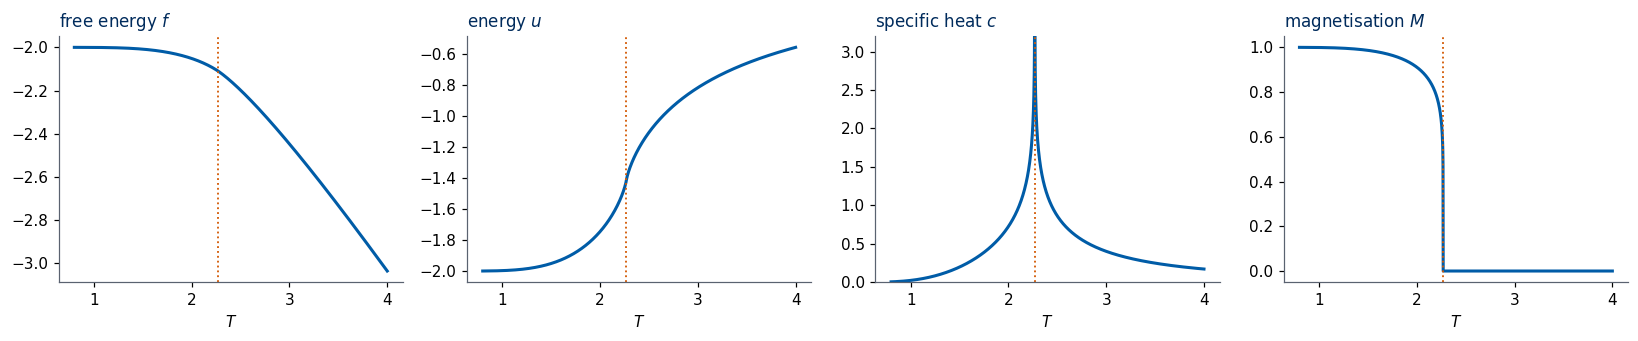

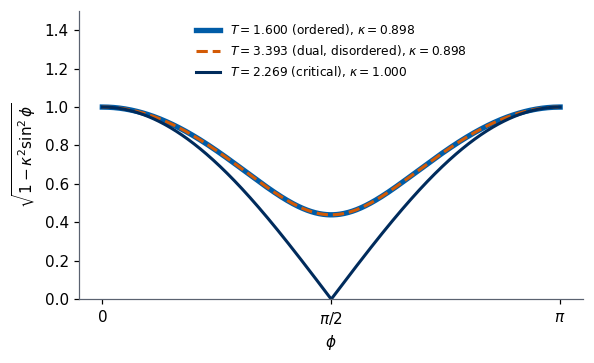

In [13]:
T = np.linspace(0.8, 4.0, 1601); T = T[np.abs(T - TC) > 1e-4]
f = np.array([f_onsager(t) for t in T]); u = u_elliptic(T); c = np.gradient(u, T); M = M_yang(T)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (y, lab) in zip(axes, [(f, "free energy $f$"), (u, "energy $u$"), (c, "specific heat $c$"), (M, "magnetisation $M$")]):
    if y is c:
        for side in (T < TC, T > TC):
            ax.plot(T[side], y[side], color=UJBlue, lw=2)
        ax.set_ylim(0, 3.2)
    else:
        ax.plot(T, y, color=UJBlue, lw=2)
    ax.axvline(TC, color=DSOrange, ls=":", lw=1.2); ax.set_xlabel("$T$"); ax.set_title(lab, loc="left")
plt.tight_layout(); plt.show()

phi_ = np.linspace(0, np.pi, 801)
T1 = 1.6; T1d = 1 / K_dual(1 / T1)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for Tv, col, ls, lw, name in [(T1, UJBlue, "-", 3.5, "ordered"), (T1d, DSOrange, "--", 2, "dual, disordered"), (TC, UJNavy, "-", 2, "critical")]:
    k = kappa(1 / Tv)
    ax.plot(phi_, np.sqrt(np.clip(1 - k**2 * np.sin(phi_)**2, 0, None)), color=col, ls=ls, lw=lw,
            label=rf"$T={Tv:.3f}$ ({name}), $\kappa={k:.3f}$")
ax.set_xticks([0, np.pi / 2, np.pi], ["0", r"$\pi/2$", r"$\pi$"]); ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\sqrt{1-\kappa^2\sin^2\phi}$"); ax.set_ylim(0, 1.5); ax.legend(frameon=False, fontsize=8, loc="upper center")
plt.tight_layout(); plt.show()

$f$ looks perfectly smooth; $u$ is continuous but has a vertical tangent at $T_c$; the specific heat, the derivative of $u$ with respect to $T$, diverges. The singularity of $f$ is in its
**second** derivative: a continuous (second-order) transition.

<hr/>
## 7. Energy at the critical point

### 7.1 The elliptic formula at $T_c$
At $T_c$ the prefactor of $K_1$ in equation (54) vanishes, because
$$
\sinh 2K_c = 1 \;\Rightarrow\; \cosh^2 2K_c = 2 \;\Rightarrow\; \tanh^22K_c = \tfrac12 \;\Rightarrow\; 2\tanh^22K_c - 1 = 0 . \tag{57}
$$
It kills the logarithmic divergence of $K_1$ as $\kappa$ approaches 1, and
$$u(T_c) = -\coth2K_c = -\frac{\cosh 2K_c}{\sinh 2K_c} = -\sqrt2 . \tag{58}$$
Numerically, equation (54) is evaluated ever closer to $T_c$ from both sides and compared with the central difference of the integral formula in $\beta$ at $T_c$.

In [14]:
for eps in (1e-3, 1e-6, 1e-9):
    print(f"u(T_c (1 -/+ {eps:.0e})) = {u_elliptic(TC*(1-eps)):.10f}, {u_elliptic(TC*(1+eps)):.10f}")
print(f"-sqrt(2)                = {-np.sqrt(2):.10f}")
b, db = KC, 1e-5
u_int = ((b + db) * f_onsager(1/(b + db)) - (b - db) * f_onsager(1/(b - db))) / (2 * db)
print(f"from the integral, central difference in beta at T_c: {u_int:.8f}")

u(T_c (1 -/+ 1e-03)) = -1.4223925854, -1.4060346096
u(T_c (1 -/+ 1e-06)) = -1.4142294932, -1.4141976315
u(T_c (1 -/+ 1e-09)) = -1.4142135861, -1.4142135387
-sqrt(2)                = -1.4142135624
from the integral, central difference in beta at T_c: -1.41421356


### 7.2 The value from duality
The same number follows from the duality of Section 5 alone, without Onsager's formula. Differentiate the duality identity (46) with respect to $K$. Since $\varphi$ is $\ln Z/N$, equation (44), and the derivative of $\ln Z$ with respect to $\beta$ is $-\langle H\rangle$,
$$
\varphi'(K) = -u(K) \equiv \varepsilon(K), \tag{59}
$$
where, with $J$ set to 1, $\varepsilon$ is twice the nearest-neighbour correlation $\langle s_is_j\rangle_{\rm nn}$ (two bonds per spin). Differentiating equation (46) gives
$$
\varepsilon(K) - 2\tanh K = \big(\varepsilon(K^*) - 2\big)\frac{dK^*}{dK}. \tag{60}
$$
Differentiating equation (45),
$$
-2e^{-2K^*}dK^* = \frac{dK}{\cosh^2K}\ \Rightarrow\ \frac{dK^*}{dK} = -\frac{1}{2\tanh K\cosh^2K} = -\frac{1}{\sinh 2K}, \tag{61}
$$
which is $-1$ at $K_c$ by equation (49). At the self-dual point $K$ and $K^*$ both coincide with $K_c$, and **if $u$ is continuous there** (no latent heat), equation (60) becomes
$$
\varepsilon - 2\tanh K_c = -(\varepsilon - 2)\ \Rightarrow\ \varepsilon(K_c) = 1 + \tanh K_c . \tag{62}
$$
Finally, by self-duality,
$$\tanh K_c = e^{-2K_c} = \frac{1}{1+\sqrt2} = \sqrt2 - 1, \tag{63}$$
so that
$$\varepsilon(K_c) = \sqrt2,\qquad u(T_c) = -\sqrt2 . \tag{64}$$
Two exact results, $T_c$ and $u(T_c)$, thus come from a symmetry argument; each step of the derivation is evaluated numerically below.

In [15]:
h = 1e-7
print(f"dK*/dK at K_c (finite difference) = {(K_dual(KC + h) - K_dual(KC - h)) / (2*h):.8f}   (exact: -1/sinh 2K_c = {-1/np.sinh(2*KC):.8f})")
print(f"tanh K_c = {np.tanh(KC):.12f},  e^(-2K_c) = {np.exp(-2*KC):.12f},  sqrt2 - 1 = {np.sqrt(2)-1:.12f}")
print(f"1 + tanh K_c = {1 + np.tanh(KC):.12f}   vs   -u(T_c) from the elliptic formula = {-u_elliptic(TC*(1+1e-12)):.12f}")
# the differentiated identity at several K (not only at K_c), with epsilon from the elliptic formula
for K in (0.3, 0.4, 0.43, 0.45, 0.5, 0.6):
    Ks = K_dual(K)
    lhs = -u_elliptic(1/K) - 2*np.tanh(K)
    rhs = (-u_elliptic(1/Ks) - 2) * (-1/np.sinh(2*K))
    print(f"K = {K:.4f}:  eps(K) - 2 tanh K = {lhs:+.10f}   (eps(K*) - 2) dK*/dK = {rhs:+.10f}")

dK*/dK at K_c (finite difference) = -1.00000000   (exact: -1/sinh 2K_c = -1.00000000)
tanh K_c = 0.414213562373,  e^(-2K_c) = 0.414213562373,  sqrt2 - 1 = 0.414213562373
1 + tanh K_c = 1.414213562373   vs   -u(T_c) from the elliptic formula = 1.414213562342
K = 0.3000:  eps(K) - 2 tanh K = +0.1218738459   (eps(K*) - 2) dK*/dK = +0.1218738459
K = 0.4000:  eps(K) - 2 tanh K = +0.3461812792   (eps(K*) - 2) dK*/dK = +0.3461812792
K = 0.4300:  eps(K) - 2 tanh K = +0.4897691028   (eps(K*) - 2) dK*/dK = +0.4897691028
K = 0.4500:  eps(K) - 2 tanh K = +0.6692477955   (eps(K*) - 2) dK*/dK = +0.6692477955
K = 0.5000:  eps(K) - 2 tanh K = +0.8213302608   (eps(K*) - 2) dK*/dK = +0.8213302608
K = 0.6000:  eps(K) - 2 tanh K = +0.8349870437   (eps(K*) - 2) dK*/dK = +0.8349870437


<hr/>
## 8. Critical exponents

Near $T_c$ the exact formulas behave as powers (or logarithms) of the reduced temperature
$$t = \frac{T-T_c}{T_c}, \tag{65}$$
and the exponents of these laws can be read off numerically.

For the magnetisation,
$$M\sim(-t)^\beta, \tag{66}$$
we fit $\ln M$ against $\ln(-t)$ close to $T_c$, and we also look at the *local* slope $d\ln M/d\ln(-t)$, which must tend to $\beta$.

The specific heat diverges logarithmically,
$$c\sim -A\ln|t|, \tag{67}$$
which corresponds to a vanishing exponent $\alpha$. We fit
$$c = -A\ln|t| + B_\pm \tag{68}$$
on both sides of $T_c$ and compare the fitted amplitude with the exact value
$$A = \frac{2}{\pi}\Big(\frac{2}{T_c}\Big)^2 . \tag{69}$$
Here $c$ is obtained from the elliptic $u$ by a central difference with a step much smaller than $|T-T_c|$.

beta from a fit of ln M vs ln(-t), |t| < 1e-4:  0.124999    (1/8 = 0.125)
local slope d lnM / d ln|t| at |t| = 1e-2, 1e-4, 1e-6, 1e-8: 0.12310, 0.12498, 0.12500, 0.12500
T < T_c:  c = -A ln|t| + B  with  A = 0.494517,  B = -0.3060
T > T_c:  c = -A ln|t| + B  with  A = 0.494656,  B = -0.3078
exact amplitude: A = (2/pi)(2/T_c)^2 = 0.494539


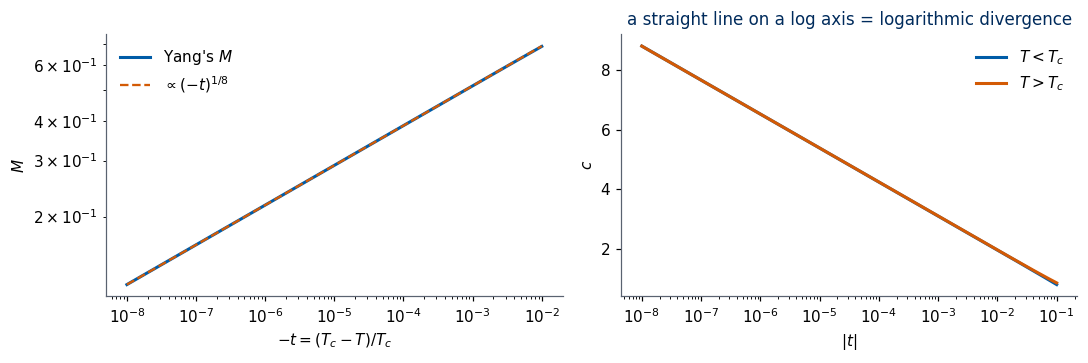

In [16]:
tt = np.logspace(-8, -2, 40)                                   # |t|
Mt = M_yang(TC * (1 - tt))
slope_fit = np.polyfit(np.log(tt[tt < 1e-4]), np.log(Mt[tt < 1e-4]), 1)[0]
local = np.gradient(np.log(Mt), np.log(tt))
print(f"beta from a fit of ln M vs ln(-t), |t| < 1e-4:  {slope_fit:.6f}    (1/8 = {1/8})")
print("local slope d lnM / d ln|t| at |t| = 1e-2, 1e-4, 1e-6, 1e-8:",
      ", ".join(f"{np.interp(np.log(x), np.log(tt), local):.5f}" for x in (1e-2, 1e-4, 1e-6, 1e-8)))

def c_exact(T, rel=1e-4):
    # c = du/dT by a central difference with step rel*|T - T_c|
    hstep = rel * np.abs(T - TC)
    return (u_elliptic(T + hstep) - u_elliptic(T - hstep)) / (2 * hstep)

A_exact = 2 / np.pi * (2 / TC)**2
for side, sgn in (("T < T_c", -1), ("T > T_c", +1)):
    tfit = np.logspace(-9, -4, 30)
    cfit = c_exact(TC * (1 + sgn * tfit))
    A, B = np.polyfit(-np.log(tfit), cfit, 1)
    print(f"{side}:  c = -A ln|t| + B  with  A = {A:.6f},  B = {B:+.4f}")
print(f"exact amplitude: A = (2/pi)(2/T_c)^2 = {A_exact:.6f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].loglog(tt, Mt, color=UJBlue, lw=2, label="Yang's $M$")
ax[0].loglog(tt, tt**0.125 * Mt[0] / tt[0]**0.125, color=DSOrange, ls="--", lw=1.5, label=r"$\propto(-t)^{1/8}$")
ax[0].set_xlabel(r"$-t = (T_c - T)/T_c$"); ax[0].set_ylabel("$M$"); ax[0].legend(frameon=False)
tl = np.logspace(-8, -1, 200)
ax[1].semilogx(tl, c_exact(TC * (1 - tl)), color=UJBlue, lw=2, label="$T<T_c$")
ax[1].semilogx(tl, c_exact(TC * (1 + tl)), color=DSOrange, lw=2, label="$T>T_c$")
ax[1].set_xlabel(r"$|t|$"); ax[1].set_ylabel("$c$"); ax[1].legend(frameon=False)
ax[1].set_title("a straight line on a log axis = logarithmic divergence")  # the two sides nearly coincide: B_- and B_+ are close
plt.tight_layout(); plt.show()

### 8.1 Exponents $\eta$ and $\nu$ from the transfer matrix
The strips of Section 3 give two more exponents, independently of Onsager's formula.

The exponent $\eta$ follows from the correlation length at $T_c$, which on a strip is proportional to the width. Conformal invariance of the critical point fixes the constant on a periodic strip,
$$\xi_L = \frac{L}{\pi\eta}, \tag{70}$$
so
$$\eta_L = \frac{L}{\pi\,\xi_L(T_c)} \tag{71}$$
should tend to $\eta$, whose exact value is 1/4.

The exponent $\nu$ follows from finite-size scaling. Near $T_c$, $\xi_L/L$ is a function of $L^{1/\nu}t$ only, so its slope at $T_c$ grows as
$$\frac{d(\xi_L/L)}{dT}\Big|_{T_c}\propto L^{1/\nu}. \tag{72}$$
The exact value of $\nu$ is 1.

As a by-product we test the convergence of the free energy at $T_c$,
$$f_L - f = -\frac{\pi\,c_{\rm CFT}\,T_c}{6L^2}, \tag{73}$$
where the central charge $c_{\rm CFT}$ of conformal field theory (CFT) for the Ising universality class is one half; in other words
$$L^2(f_L - f)\to-\frac{\pi T_c}{12}. \tag{74}$$

In [17]:
print(" L    eta_L = L/(pi xi_L(T_c))   L^2 (f_L - f)(T_c)    slope d(xi_L/L)/dT at T_c")
slopes, Lv = [], [4, 6, 8, 10, 12]
t0 = time.perf_counter()
for L in Lv:
    l0, l1 = lambda01(L, KC)
    xi = 1 / np.log(l0 / l1)
    dT = 1e-4
    s = (xi_over_L(L, TC + dT) - xi_over_L(L, TC - dT)) / (2 * dT)
    slopes.append(abs(s))
    print(f"{L:2d}       {L/(np.pi*xi):.6f}               {L**2 * (-TC*np.log(l0)/L - f_onsager(TC)):+.6f}            {s:+.4f}")
print(f"(computed in {time.perf_counter()-t0:.1f} s)        -pi T_c/12 = {-np.pi*TC/12:.6f}")
inv_nu = np.diff(np.log(slopes)) / np.diff(np.log(Lv))
print("1/nu from consecutive pairs of L:", ", ".join(f"{v:.4f}" for v in inv_nu))

 L    eta_L = L/(pi xi_L(T_c))   L^2 (f_L - f)(T_c)    slope d(xi_L/L)/dT at T_c
 4       0.257845               -0.620440            -2.3677
 6       0.253121               -0.604507            -3.6854
 8       0.251679               -0.599671            -4.9703
10       0.251056               -0.597589            -6.2438


12       0.250727               -0.596492            -7.5122
(computed in 1.9 s)        -pi T_c/12 = -0.594071
1/nu from consecutive pairs of L: 1.0912, 1.0397, 1.0222, 1.0144


All three columns converge, monotonically in $L$, towards the exact values, 1/4 for $\eta$ and 1 for $\nu$, and towards the conformal prediction of equation (74). Together with the vanishing $\alpha$ (logarithm) and $\beta$ of 1/8, the scaling relations
$$\gamma = \nu(2-\eta),\qquad \alpha + 2\beta + \gamma = 2 \tag{75}$$
give the remaining exponent:

In [18]:
nu, eta, alpha, beta_ = 1, 0.25, 0, 0.125
gamma = nu * (2 - eta)
print(f"gamma = nu (2 - eta) = {gamma}   (= 7/4);   Rushbrooke check alpha + 2 beta + gamma = {alpha + 2*beta_ + gamma}")

gamma = nu (2 - eta) = 1.75   (= 7/4);   Rushbrooke check alpha + 2 beta + gamma = 2.0


<hr/>
## 9. Mean-field theory

Mean-field (MF) theory replaces the neighbours of each spin by their average $m$: each spin feels the field $zm$, where $z$, the number of neighbours, is 4, so
$$
m = \tanh\Big(\frac{4m}{T}\Big). \tag{76}
$$
Zero magnetisation is always a solution; a non-zero one exists when the slope of the right-hand side at the origin exceeds 1, that is below
$$T_c^{\rm MF} = 4 . \tag{77}$$
Near $T_c^{\rm MF}$ the expansion
$$\tanh x\approx x - \frac{x^3}{3} \tag{78}$$
gives
$$m \approx \frac4Tm - \frac13\Big(\frac4T\Big)^3m^3,\qquad m^2\approx \frac{3\big(\frac4T-1\big)}{\big(\frac4T\big)^3}, \tag{79}$$
so
$$m\sim\big(1 - T/T_c^{\rm MF}\big)^{1/2},\qquad \beta_{\rm MF} = \tfrac12 . \tag{80}$$
The mean-field energy per spin,
$$u_{\rm MF} = -\frac z2m^2 = -2m^2, \tag{81}$$
vanishes above $T_c^{\rm MF}$ and has a finite slope below, which gives a **jump** in $c$ instead of a divergence. $T_c^{\rm MF}$, $\beta_{\rm MF}$ and the specific heat just below $T_c^{\rm MF}$ are also found numerically, and the mean-field magnetisation is plotted together with Yang's exact $M$.

T_c (mean field, numerical) = 4.000000     exact 2D: T_c = 2.269185     ratio = 1.7627
beta_MF from a fit near T_c^MF: 0.49998
mean-field specific heat just below T_c^MF: 1.49640, 1.49996   (and exactly 0 above)


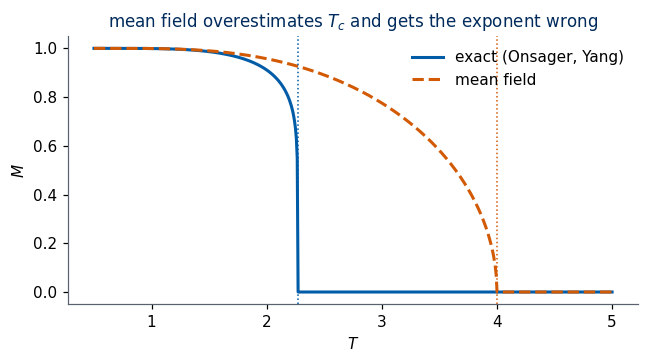

In [19]:
def m_meanfield(T):
    # largest solution of m = tanh(4 m / T)
    if 4 / T <= 1:
        return 0.0
    return brentq(lambda m: m - np.tanh(4 * m / T), 1e-12, 1.0)

# T_c^MF: the largest T with a non-zero solution (found by bisection, threshold m > 1e-6)
lo, hi = 2.0, 6.0
for _ in range(80):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if m_meanfield(mid) > 1e-6 else (lo, mid)
print(f"T_c (mean field, numerical) = {lo:.6f}     exact 2D: T_c = {TC:.6f}     ratio = {lo/TC:.4f}")

tt = np.logspace(-8, -3, 20)
mf = np.array([m_meanfield(4 * (1 - x)) for x in tt])
print(f"beta_MF from a fit near T_c^MF: {np.polyfit(np.log(tt), np.log(mf), 1)[0]:.5f}")
cm = [(-2*m_meanfield(4*(1-x))**2 + 2*m_meanfield(4*(1-2*x))**2) / (4*x) for x in (1e-3, 1e-5)]
print("mean-field specific heat just below T_c^MF:", ", ".join(f"{v:.5f}" for v in cm), "  (and exactly 0 above)")

T = np.linspace(0.5, 5, 600)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(T, M_yang(T), color=UJBlue, lw=2, label="exact (Onsager, Yang)")
ax.plot(T, [m_meanfield(t) for t in T], color=DSOrange, lw=2, ls="--", label="mean field")
ax.axvline(TC, color=UJBlue, ls=":", lw=1); ax.axvline(4, color=DSOrange, ls=":", lw=1)
ax.set_xlabel("$T$"); ax.set_ylabel("$M$"); ax.legend(frameon=False)
ax.set_title("mean field overestimates $T_c$ and gets the exponent wrong")
plt.tight_layout(); plt.show()

Mean field neglects fluctuations; in 2D they are strong, they lower $T_c$ and change $\beta$ from 1/2 to 1/8. The same
mean-field equation appears again in energy-based models, as a **recurrent $\tanh$ network**.

<hr/>
## 10. The triangular lattice and universality

Add one diagonal bond to every plaquette: each spin now has six neighbours. In the transfer matrix this adds the term
$$K\sum_is_is'_{i+1} \tag{82}$$
to the exponent of equation (29) (flag `lattice="triangular"`; $\mathsf V$ is no longer symmetric, so we use a general eigensolver). The exact results are the critical temperature
$$T_c^{\triangle} = \frac{4}{\ln3} \tag{83}$$
and *the same exponents* as on the square lattice. We test both with the crossing method of Section 3 and with $\eta_L$.

One geometric correction is needed. In the triangular lattice the columns are $\sqrt3/2$ apart (the sites of one column are at distance 1), so the physical correlation length is $\xi_L$ multiplied by $\sqrt3/2$, and
$$\eta_L = \frac{L}{\pi\,\tfrac{\sqrt3}{2}\,\xi_L}. \tag{84}$$

In [20]:
print(" L, L+2   crossing T*(L)     eta at the crossing")
t0 = time.perf_counter()
for L in (4, 6, 8, 10):
    Tx = brentq(lambda T: xi_over_L(L, T, "triangular") - xi_over_L(L + 2, T, "triangular"), 3.0, 4.2, xtol=1e-12)
    xi = xi_over_L(L + 2, Tx, "triangular") * (L + 2)
    print(f"{L:2d}, {L+2:2d}   {Tx:.8f}       {(L + 2) / (np.pi * np.sqrt(3) / 2 * xi):.5f}")
print(f"4/ln 3 = {4/np.log(3):.8f}    ({time.perf_counter()-t0:.1f} s)")

 L, L+2   crossing T*(L)     eta at the crossing
 4,  6   3.64236593       0.25076


 6,  8   3.64117712       0.25016


 8, 10   3.64101598       0.25006


10, 12   3.64097803       0.25002
4/ln 3 = 3.64095691    (14.4 s)


The critical temperature is different (more neighbours, more order), the exponent $\eta$ is the same: $T_c$ is a lattice detail, the exponents are
the physics. A network trained on one lattice can only transfer to another lattice to the extent that it has learned something universal — the
interpretability question of the Chinese-room part of the lecture.

<hr/>
## 11. Summary

The table collects the statements of the slides and the section where each of them is computed.

| slide statement | where it is checked |
|---|---|
| finite lattice: $\ln Z$ smooth | Section 1 (brute force, $4\times4$) |
| transfer matrix of the chain, equations (18) and (21); finite $\xi$ in 1D | Section 2 |
| $f_L$ converges to $f$, the peak of $c_L$ grows, crossings of $\xi_L/L$ approach $T_c$ | Section 3 |
| closed graphs, equations (37) and (39), the same on the dual lattice | Section 4 |
| duality, equations (47) and (49); $\kappa$ the same at $K$ and $K^*$ | Section 5 |
| $u$ from the integral agrees with equation (54) | Section 6 |
| $u(T_c)$ of equation (58), also from duality, equation (64) | Section 7 |
| exponents: $\beta$ 1/8, $\alpha$ 0 (logarithm, amplitude (69)), $\eta$ 1/4, $\nu$ 1 | Section 8 |
| mean field: equations (77) and (80), jump in $c$ | Section 9 |
| triangular lattice: equation (83), same $\eta$ | Section 10 |
<hr/>
## Exercises

### Exercise 1 — the 1D chain in a field
Using the transfer matrix, compute the magnetisation per spin of the infinite chain,
$$m = \frac{\partial\ln\lambda_+}{\partial\tilde h}, \tag{85}$$
numerically (finite difference) and compare with
$$m = \frac{\sinh\tilde h}{\sqrt{\sinh^2\tilde h + e^{-4K}}}. \tag{86}$$
Plot $m(h)$ at several temperatures: is there a spontaneous magnetisation as the field goes to zero from above, at any positive temperature?

#### Solution

K = 0.5, beta h = 0.1:  m numerical = 0.26271701,  equation (86) = 0.26271701
K = 1.0, beta h = 0.05:  m numerical = 0.34668443,  equation (86) = 0.34668443
K = 2.0, beta h = 0.01:  m numerical = 0.47921470,  equation (86) = 0.47921470


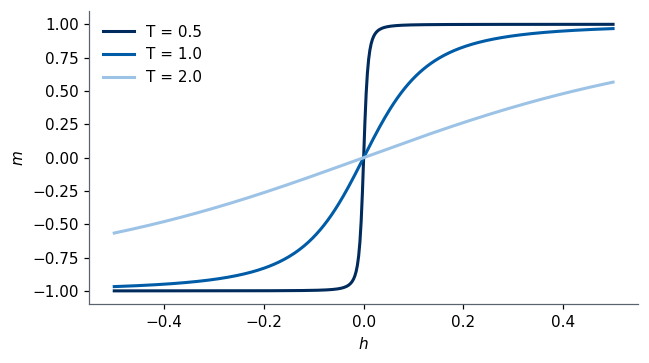

In [21]:
def lam_plus(K, ht):
    return np.exp(K) * np.cosh(ht) + np.sqrt(np.exp(2 * K) * np.sinh(ht)**2 + np.exp(-2 * K))

for K, ht in [(0.5, 0.1), (1.0, 0.05), (2.0, 0.01)]:
    d = 1e-6
    m_num = (np.log(lam_plus(K, ht + d)) - np.log(lam_plus(K, ht - d))) / (2 * d)
    m_exact = np.sinh(ht) / np.sqrt(np.sinh(ht)**2 + np.exp(-4 * K))
    print(f"K = {K}, beta h = {ht}:  m numerical = {m_num:.8f},  equation (86) = {m_exact:.8f}")

hgrid = np.linspace(-0.5, 0.5, 401)
fig, ax = plt.subplots(figsize=(6, 3.4))
for T, col in [(0.5, UJNavy), (1.0, UJBlue), (2.0, "#9CC3E6")]:
    K = 1 / T; ht = hgrid / T
    ax.plot(hgrid, np.sinh(ht) / np.sqrt(np.sinh(ht)**2 + np.exp(-4 * K)), color=col, lw=2, label=f"T = {T}")
ax.set_xlabel("$h$"); ax.set_ylabel("$m$"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

$m(h)$ is a smooth odd function that vanishes at zero field for every positive temperature: no spontaneous magnetisation, only an ever steeper curve as the temperature goes to zero. The slope at zero field,
$$\frac{\partial m}{\partial h}\Big|_{h=0} = \beta e^{2K}, \tag{87}$$
grows exponentially in $K$, but is finite for every positive temperature.

### Exercise 2 — the specific-heat peak of strips
Using `strip` from Section 3, plot the maximum of $c_L$ against $\ln L$. The logarithmic divergence of equation (67), combined with
$$|t|\sim\frac1L \tag{88}$$
(because $\nu$ is 1), predicts
$$c_{\max}(L)\approx A\ln L + \text{const}. \tag{89}$$
Fit the slope and compare with $A$ found in Section 8.

#### Solution

In [22]:
cmax = []
t0 = time.perf_counter()
Lex = [4, 6, 8, 10, 12]
for L in Lex:
    if L in strip:
        cmax.append(strip[L]["c"][2:-2].max())
    else:                                     # L = 12 was not in the scan: maximise c_L near its peak
        def cL(T, L=L, d=2e-3):
            fm, f0, fp = (-(T + s) * np.log(lambda01(L, 1 / (T + s))[0]) / L for s in (-d, 0, d))
            return -T * (fp - 2 * f0 + fm) / d**2
        from scipy.optimize import minimize_scalar
        res = minimize_scalar(lambda T: -cL(T), bounds=(2.24, 2.30), method="bounded", options={"xatol": 1e-3})
        cmax.append(-res.fun)
print(f"(L = 12 peak search: {time.perf_counter()-t0:.1f} s)")
slope = np.polyfit(np.log(Lex[1:]), cmax[1:], 1)[0]
for L, cm in zip(Lex, cmax):
    print(f"L = {L:2d}: c_max = {cm:.4f}")
print(f"slope of c_max vs ln L (L = 6..12): {slope:.4f};   A from Section 8: {A_exact:.4f}")

(L = 12 peak search: 10.4 s)
L =  4: c_max = 0.8728
L =  6: c_max = 1.0739
L =  8: c_max = 1.2160
L = 10: c_max = 1.3262
L = 12: c_max = 1.4170
slope of c_max vs ln L (L = 6..12): 0.4947;   A from Section 8: 0.4945


The slope approaches $A$ as $L$ grows (the small strips still carry visible corrections). The specific-heat peak of a finite lattice grows only
**logarithmically** with its size — one reason why a Monte Carlo study (and the CNN of Lab 011) sees a broad, shifted feature rather than a sharp
singularity.

### Exercise 3 (open) — the quantum connection
For the strip, $\mathsf V$ can be written, like an imaginary-time evolution operator, as a product of diagonal matrices and single-spin factors,
$$\mathsf V = e^{\frac K2\sum_i s_is_{i+1}}\Big[\prod_i\big(e^{K}\mathbb 1 + e^{-K}\sigma^x_i\big)\Big]e^{\frac K2\sum_i s_is_{i+1}} . \tag{90}$$
Show that
$$e^{K}\mathbb 1 + e^{-K}\sigma^x = \sqrt{2\sinh2K}\;e^{K^*\sigma^x}, \tag{91}$$
so that the transfer matrix is a product of a classical Ising coupling along the column and a **transverse field** of strength $K^*$. Verify the identity numerically for a few values of $K$.
This is the bridge to the transverse-field Ising chain used later in the course.

#### Solution

In [23]:
sx = np.array([[0.0, 1.0], [1.0, 0.0]])
from scipy.linalg import expm
for K in (0.2, KC, 0.8):
    lhs = np.exp(K) * np.eye(2) + np.exp(-K) * sx
    rhs = np.sqrt(2 * np.sinh(2 * K)) * expm(K_dual(K) * sx)
    print(f"K = {K:.4f}:  max |lhs - rhs| = {np.abs(lhs - rhs).max():.1e}")

K = 0.2000:  max |lhs - rhs| = 1.1e-16
K = 0.4407:  max |lhs - rhs| = 2.2e-16
K = 0.8000:  max |lhs - rhs| = 1.1e-16


Proof: the exponential of $\sigma^x$ is
$$e^{K^*\sigma^x} = \cosh K^*\,\mathbb1 + \sinh K^*\,\sigma^x , \tag{92}$$
and from equation (45) one gets
$$\tanh K^* = e^{-2K}, \tag{93}$$
so the ratio of the coefficients is right; the prefactor follows from
$$\cosh K^*\sqrt{2\sinh2K} = e^{K}, \tag{94}$$
which the numerical check confirms. At the self-dual point, where $K$ and $K^*$ both equal $K_c$, the column coupling and the transverse field are equal — the critical point of the quantum chain.